# Phần 5 (Giai đoạn 4). Phân tích SQL, Chế biến Đặc trưng và Khám phá Dữ liệu Khối ngành Công nghệ (`src/data_processing.py`)

Notebook này trình bày trọn vẹn **Giai đoạn 4** của dự án, kết hợp ba nhiệm vụ cốt lõi:
1. **Truy vấn phân tích chuyên sâu bằng SQL** trực tiếp trên cơ sở dữ liệu `ady` đã làm sạch ở Giai đoạn 3.
2. **Bóc tách từng hàm và từng bước nhỏ trong `src/data_processing.py`** (sử dụng các câu lệnh Python và Pandas cơ bản, tường minh, không dùng Regex hay Lambda phức tạp) để lọc đúng **5 phân nhóm ngành Công nghệ – Kỹ thuật**, tạo bộ đặc trưng sạch (**478 dòng, 0 ô trống**) và chia Tập Học (**262 dòng**) / Tập Kiểm Thử (**151 dòng**).
3. **Phân tích khám phá dữ liệu (EDA)** bằng thống kê và biểu đồ trực quan nhằm kiểm chứng giả thuyết và làm cơ sở lựa chọn mô hình Học máy ở File 6.

**Luồng làm việc:**

    Giai đoạn 4. Phân tích SQL, Chế biến Đặc trưng & EDA Khối Công nghệ
    ├── 5.1 Truy vấn SQL phân tích các chỉ số tuyển sinh trên CSDL ady
    ├── 5.2 Ba hàm phụ chuẩn hóa chuỗi và phân loại 5 phân nhóm Công nghệ
    ├── 5.3 Bóc tách từng bước ghép bảng & chế biến đặc trưng (load_and_preprocess_data)
    └── 5.4 Phân tích khám phá dữ liệu (EDA) & Cơ sở đề xuất mô hình Học máy

---
### 5.1. Truy vấn SQL Phân tích Nghiệp vụ Tuyển sinh trên CSDL `ady`

Trước khi đưa dữ liệu sang Pandas để chế biến đặc trưng cho AI, ta sử dụng các câu lệnh `SELECT` phân tích (`JOIN`, `CASE WHEN`, `GROUP BY`, `CTE`) trực tiếp trên SQL Server để nắm bắt bức tranh tổng quan về phổ điểm, chỉ tiêu và điểm chuẩn.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from config import DB_CONNECTION_STRING

engine = create_engine(DB_CONNECTION_STRING)
print("Đã kết nối CSDL 'ady' sẵn sàng cho truy vấn phân tích SQL & chế biến đặc trưng.")

Đã kết nối CSDL 'ady' sẵn sàng cho truy vấn phân tích SQL & chế biến đặc trưng.

**Truy vấn SQL 1 — So sánh sức cạnh tranh phổ điểm giữa khối truyền thống (`A00`, `A01`, `D01`) và khối Tin học mới (`X06`, `X26`) giai đoạn 2025–2026:**

In [2]:
q_sql_1 = '''
SELECT Nam, Ma_To_Hop,
       CASE WHEN Ma_To_Hop IN ('X06', 'X26') THEN N'Tổ hợp Tin học mới'
            ELSE N'Tổ hợp truyền thống' END AS Nhom_To_Hop,
       Diem_Trung_Binh, Tong_So_Thi_Sinh,
       CAST(So_Luong_Tren_25 * 100.0 / NULLIF(Tong_So_Thi_Sinh, 0) AS DECIMAL(5,2)) AS Ty_Le_Tren_25_Pct,
       CAST(So_Luong_Tren_27 * 100.0 / NULLIF(Tong_So_Thi_Sinh, 0) AS DECIMAL(5,2)) AS Ty_Le_Tren_27_Pct
FROM ThongKePhoDiem_Cache
WHERE Nam IN (2025, 2026) AND Ma_To_Hop IN ('A00', 'A01', 'D01', 'X06', 'X26')
ORDER BY Nam, Ty_Le_Tren_25_Pct DESC
'''
print(pd.read_sql(q_sql_1, engine).to_string(index=False))

 Nam Ma_To_Hop         Nhom_To_Hop  Diem_Trung_Binh  Tong_So_Thi_Sinh  Ty_Le_Tren_25_Pct  Ty_Le_Tren_27_Pct
2025       A00 Tổ hợp truyền thống            20.03            143615              15.75               6.24
2025       X06  Tổ hợp Tin học mới            19.65              1378              13.21               4.43
2025       A01 Tổ hợp truyền thống            19.47            134405               7.23               1.49
2025       X26  Tổ hợp Tin học mới            19.01              2264               6.89               1.90
2025       D01 Tổ hợp truyền thống            19.17            323036               2.46               0.19
2026       A00 Tổ hợp truyền thống            19.91            175232              12.60               3.15
2026       X06  Tổ hợp Tin học mới            18.73              6188               9.21               2.39
2026       X26  Tổ hợp Tin học mới            19.27              3944               8.14               2.23
2026       A01 Tổ hợp truyền

**Nhận xét:** Nhờ bước đồng bộ mã `X06`, `X26` ở Giai đoạn 3, bảng Cache cho thấy quy mô thí sinh dự thi tổ hợp Tin học năm 2026 tăng gấp gần 3 lần so với năm 2025, đồng thời tổ hợp `X06` (Toán – Lý – Tin) có tỷ lệ thí sinh đạt từ 25 điểm trở lên tiệm cận nhóm khối kỹ thuật truyền thống `A01`.

**Truy vấn SQL 2 — Top 10 trường đại học có tổng chỉ tiêu dành cho xét điểm thi THPT lớn nhất năm 2026 (`JOIN` bảng `ChiTieuTruong` và `DanhMucTruong`):**

In [3]:
q_sql_2 = '''
SELECT TOP 10
       c.ma_truong,
       t.ten_truong,
       COUNT(c.id) AS so_chuong_trinh,
       SUM(c.chi_tieu) AS tong_chi_tieu_2026,
       CAST(SUM(c.chi_tieu * ISNULL(c.ty_le_chi_tieu_thpt, 0.5)) AS INT) AS chi_tieu_thpt_2026,
       CAST(AVG(ISNULL(c.ty_le_chi_tieu_thpt, 0.5)) * 100.0 AS DECIMAL(5,1)) AS ty_le_thpt_tb_pct
FROM ChiTieuTruong c
JOIN DanhMucTruong t ON c.ma_truong = t.ma_truong
WHERE c.nam_hoc = 2026
GROUP BY c.ma_truong, t.ten_truong
ORDER BY chi_tieu_thpt_2026 DESC
'''
print(pd.read_sql(q_sql_2, engine).to_string(index=False))

ma_truong                      ten_truong  so_chuong_trinh  tong_chi_tieu_2026  chi_tieu_thpt_2026  ty_le_thpt_tb_pct
      PKA                Đại học Phenikaa               81               15661                7830               50.0
      DCN      Đại học Công nghiệp Hà Nội               72                8300                5395               65.0
      BKA        Đại học Bách khoa Hà Nội               68                9430                4243               45.0
      DKK ĐH Kinh tế Kỹ thuật Công nghiệp               27                6020                4214               70.0
      KHA        Đại học Kinh tế Quốc dân               88                8455                3382               40.0
      HVN   Học viện Nông nghiệp Việt Nam               23                8184                3273               40.0
      HTC              Học viện Tài chính               35                5740                2870               50.0
      NHH              Học viện Ngân hàng               

**Nhận xét:** Kết quả `JOIN` cho thấy sự khác biệt lớn về chính sách phân bổ chỉ tiêu giữa các trường: một số trường dành trên 50%–60% chỉ tiêu cho điểm thi THPT, trong khi các trường tự chủ tốp đầu như ĐH Bách khoa Hà Nội hay ĐH Kinh tế Quốc dân chỉ dành tỷ lệ nhỏ hơn cho phương thức xét điểm thi THPT, trực tiếp đẩy điểm chuẩn lên mức rất cao.

**Truy vấn SQL 3 — Dùng bảng tạm `WITH CTE` và hàm cửa sổ `LAG()` phân tích biến động điểm chuẩn trung bình qua các năm (2022–2025) của các trường đào tạo Công nghệ tiêu biểu:**

In [4]:
q_sql_3 = '''
WITH ThongKeTruongNam AS (
    SELECT d.ma_truong, t.ten_truong, d.nam_hoc,
           ROUND(AVG(d.diem_chuan), 2) AS diem_tb_truong,
           MAX(d.diem_chuan) AS diem_cao_nhat
    FROM DiemChuanTruong d
    JOIN DanhMucTruong t ON d.ma_truong = t.ma_truong
    WHERE d.ma_truong IN ('BKA', 'QHI', 'BVH', 'KMA', 'DCN', 'TLA')
    GROUP BY d.ma_truong, t.ten_truong, d.nam_hoc
)
SELECT ma_truong, nam_hoc, diem_tb_truong, diem_cao_nhat,
       ROUND(diem_tb_truong - LAG(diem_tb_truong) OVER (PARTITION BY ma_truong ORDER BY nam_hoc), 2) AS bien_dong_so_nam_truoc
FROM ThongKeTruongNam
WHERE nam_hoc >= 2023
ORDER BY ma_truong, nam_hoc
'''
print(pd.read_sql(q_sql_3, engine).to_string(index=False))

ma_truong  nam_hoc  diem_tb_truong  diem_cao_nhat  bien_dong_so_nam_truoc
      BKA     2023           24.79          29.42                     NaN
      BKA     2024           25.35          28.53                    0.56
      BKA     2025           25.38          29.39                    0.03
      BVH     2023           25.57          26.59                     NaN
      BVH     2024           25.32          26.40                   -0.25
      BVH     2025           23.95          26.21                   -1.37
      DCN     2023           23.21          25.52                     NaN
      DCN     2024           23.75          26.05                    0.54
      DCN     2025           21.45          26.27                   -2.30
      KMA     2023           25.60          26.20                     NaN
      KMA     2024           25.80          26.10                    0.20
      KMA     2025           24.07          24.42                   -1.73
      QHI     2023           25.63    

**Nhận xét:** Truy vấn `CTE` kết hợp `LAG()` cho thấy mặt bằng điểm chuẩn có tính quán tính lịch sử rất rõ theo từng phân tầng trường (`QHI`, `BKA`, `BVH` luôn giữ trần điểm 26–29 điểm, trong khi `DCN`, `TLA` dao động ở vùng 22–26 điểm), khẳng định `diem_nam_ngoai` và `school_avg_score` là những mỏ neo đặc trưng cực kỳ quan trọng.

---
### 5.2. Ba Hàm phụ Chuẩn hóa Chuỗi và Phân loại 5 Nhóm ngành Công nghệ (Phần 2 trong `src/data_processing.py`)

#### 5.2.1. Hàm phụ 1: `clean_text(text)` — Làm gọn tên ngành bằng lệnh chuỗi cơ bản
Khác với cách cắt bỏ toàn bộ phần trong ngoặc đơn dễ làm gộp nhầm hệ Chuẩn với hệ Tiên tiến / Chất lượng cao, hàm `clean_text` đồng bộ dấu tiếng Việt kiểu cũ/mới (`'hoá'` $\rightarrow$ `'hóa'`) và chỉ xóa các từ ghi chú chung chung.

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = text.replace('hoá', 'hóa').replace('lí', 'lý').replace('kĩ', 'kỹ').replace('thuỷ', 'thủy')
    for tu_thua in ['chương trình', 'đại trà', 'hệ chuẩn', 'cs hà nội', 'đào tạo tại hà nội']:
        text = text.replace(tu_thua, ' ')
    for ky_tu in ['-', '–', '/', ',', ';', ':', '&', '(', ')', '.', '\n', '\r']:
        text = text.replace(ky_tu, ' ')
    text = ' '.join(text.split())
    return text

for vd in ["Kỹ thuật điều khiển & Tự động hoá (Hệ chuẩn)", "Kỹ thuật Cơ điện tử (Chương trình tiên tiến)"]:
    print(f"Gốc: {vd:<48} -> Sạch: {clean_text(vd)}")

Gốc: Kỹ thuật điều khiển & Tự động hoá (Hệ chuẩn)     -> Sạch: kỹ thuật điều khiển tự động hóa
Gốc: Kỹ thuật Cơ điện tử (Chương trình tiên tiến)     -> Sạch: kỹ thuật cơ điện tử tiên tiến

#### 5.2.2. Hàm phụ 2: `gop_ma_khoi` & Hàm phụ 3: `map_standard_major` — Lọc đúng 5 Phân nhóm Công nghệ
Hàm `gop_ma_khoi` thay thế cú pháp `lambda` để nối các khối xét tuyển duy nhất bằng dấu phẩy; hàm `map_standard_major` kiểm tra danh sách từ khóa loại trừ trước (tránh nhận nhầm ngành *"Khai thác vận tải"* hay *"Sư phạm Tin"*), sau đó phân loại chính xác vào **5 nhóm ngành Công nghệ chuẩn**.

In [6]:
def gop_ma_khoi(danh_sach_khoi):
    cac_khoi_duy_nhat = danh_sach_khoi.unique()
    return ','.join(cac_khoi_duy_nhat)

TU_DIEN_NGANH = {
    'AI_DATA': ['trí tuệ nhân tạo', 'khoa học dữ liệu', 'khoa học máy tính', 'toán tin'],
    'SE_CYBER': ['công nghệ thông tin', 'kỹ thuật phần mềm', 'hệ thống thông tin', 'an toàn thông tin', 'an toàn không gian số', 'mạng máy tính', 'đa phương tiện'],
    'CHIP_IOT_HW': ['vi mạch', 'bán dẫn', 'kỹ thuật máy tính', 'hệ thống nhúng', 'iot', 'điện tử viễn thông', 'kỹ thuật điện tử', 'vi điện tử', 'công nghệ nano', 'vật lý kỹ thuật'],
    'AUTO_ELEC': ['tự động hóa', 'điều khiển', 'robot', 'cơ điện tử', 'kỹ thuật điện', 'hệ thống điện', 'năng lượng'],
    'MECH_AUTO_TECH': ['ô tô', 'cơ khí', 'chế tạo máy', 'hàng không', 'vật liệu', 'công nghệ kỹ thuật', 'kỹ thuật nhiệt', 'hạt nhân']
}

In [7]:
def map_standard_major(name):
    name = str(name).lower()
    name = name.replace('hoá', 'hóa').replace('lí', 'lý').replace('kĩ', 'kỹ').replace('thuỷ', 'thủy')
    for tu_loai_tru in ['sư phạm', 'sp ', 'tiếng anh', 'tiếng trung', 'tiếng nhật', 'tiếng pháp', 'ngôn ngữ', 'kế toán', 'luật', 'báo chí', 'xây dựng', 'vận tải', 'kinh doanh']:
        if tu_loai_tru in name:
            return 'NON_TECH'
    for ma_nhom, danh_sach_tu_khoa in TU_DIEN_NGANH.items():
        for tu_khoa in danh_sach_tu_khoa:
            if tu_khoa in name:
                return ma_nhom
    return 'NON_TECH'

for ten_thu in ["Khoa học dữ liệu và Trí tuệ nhân tạo", "Thiết kế vi mạch bán dẫn", "Khai thác vận tải", "Sư phạm Tin học"]:
    print(f"- {ten_thu:<40} -> {map_standard_major(ten_thu)}")

- Khoa học dữ liệu và Trí tuệ nhân tạo     -> AI_DATA
- Thiết kế vi mạch bán dẫn                 -> CHIP_IOT_HW
- Khai thác vận tải                        -> NON_TECH
- Sư phạm Tin học                          -> NON_TECH

---
### 5.3. Bóc tách từng bước Chế biến Đặc trưng trong `load_and_preprocess_data()`

#### Bước 1: Tạo bảng tra cứu "Điểm chuẩn năm ngoái" (`df_lag1`)
Đọc lịch sử điểm chuẩn giai đoạn 2022–2025 từ `DiemChuanTruong`, lọc giữ 5 phân nhóm Công nghệ, gom về 1 dòng mỗi ngành – trường – năm và cộng `nam_hoc + 1` để điểm năm trước khớp thẳng vào dòng của năm sau.

In [8]:
query_history = '''
    SELECT nam_hoc, ma_truong, chuong_trinh_dao_tao, ma_xet_tuyen, diem_chuan
    FROM DiemChuanTruong
    WHERE diem_chuan IS NOT NULL AND diem_chuan >= 14.0
'''
df_history_raw = pd.read_sql(query_history, engine)
df_history_raw['ma_nganh_chuan'] = df_history_raw['chuong_trinh_dao_tao'].apply(map_standard_major)
df_history_raw = df_history_raw[df_history_raw['ma_nganh_chuan'] != 'NON_TECH'].copy()
df_history_raw['clean_name'] = df_history_raw['chuong_trinh_dao_tao'].apply(clean_text)

df_history = df_history_raw.groupby(['nam_hoc', 'ma_truong', 'clean_name']).agg({'diem_chuan': 'first'}).reset_index()
df_lag1 = df_history.copy()
df_lag1['nam_hoc'] = df_lag1['nam_hoc'] + 1
df_lag1 = df_lag1.rename(columns={'diem_chuan': 'diem_nam_ngoai'})
print(f"Đã tạo bảng điểm trễ df_lag1 gồm {len(df_lag1)} chương trình đào tạo Công nghệ.")

Đã tạo bảng điểm trễ df_lag1 gồm 714 chương trình đào tạo Công nghệ.

#### Bước 2: Nối bảng Điểm chuẩn với Phổ điểm THPT (2023–2025) và tính tỷ lệ điểm giỏi trước khi gom nhóm
Tính `ti_le_tren_25` và `ti_le_tren_27` ngay trên từng khối xét tuyển trước khi `.groupby(...).agg('max')` để tránh lỗi lấy tử số của khối này chia cho mẫu số của khối khác.

In [9]:
query_sql = '''
    SELECT d.nam_hoc, d.ma_truong, d.chuong_trinh_dao_tao, d.ma_xet_tuyen,
           p.Diem_Trung_Binh, p.So_Luong_Tren_25, p.So_Luong_Tren_27, p.Tong_So_Thi_Sinh, d.diem_chuan
    FROM DiemChuanTruong d
    LEFT JOIN ThongKePhoDiem_Cache p
           ON d.nam_hoc = p.Nam AND d.ma_xet_tuyen = p.Ma_To_Hop
    WHERE d.diem_chuan IS NOT NULL AND d.diem_chuan >= 14.0 AND d.nam_hoc >= 2023
'''
df_diem_raw = pd.read_sql(query_sql, engine)
df_diem_raw['ma_nganh_chuan'] = df_diem_raw['chuong_trinh_dao_tao'].apply(map_standard_major)
df_diem_raw = df_diem_raw[df_diem_raw['ma_nganh_chuan'] != 'NON_TECH'].copy()

df_diem_raw['ti_le_tren_25'] = (df_diem_raw['So_Luong_Tren_25'] / df_diem_raw['Tong_So_Thi_Sinh']).fillna(0)
df_diem_raw['ti_le_tren_27'] = (df_diem_raw['So_Luong_Tren_27'] / df_diem_raw['Tong_So_Thi_Sinh']).fillna(0)

for col in ['Diem_Trung_Binh', 'So_Luong_Tren_25', 'So_Luong_Tren_27', 'Tong_So_Thi_Sinh', 'ti_le_tren_25', 'ti_le_tren_27']:
    df_diem_raw[col] = df_diem_raw[col].fillna(df_diem_raw[col].mean())

df_diem_raw['clean_name'] = df_diem_raw['chuong_trinh_dao_tao'].apply(clean_text)
print(f"Số dòng tổ hợp ngành Công nghệ giai đoạn 2023–2025 trước khi gộp khối: {len(df_diem_raw)} dòng")

Số dòng tổ hợp ngành Công nghệ giai đoạn 2023–2025 trước khi gộp khối: 2579 dòng

**Gộp các tổ hợp xét tuyển của cùng một ngành về 1 dòng duy nhất và ghép biến trễ năm ngoái (`diem_nam_ngoai` + phổ điểm năm ngoái):**

In [10]:
df_diem = df_diem_raw.groupby(['nam_hoc', 'ma_truong', 'clean_name']).agg({
    'diem_chuan': 'first', 'chuong_trinh_dao_tao': 'first', 'ma_nganh_chuan': 'first',
    'ma_xet_tuyen': gop_ma_khoi, 'Diem_Trung_Binh': 'max', 'So_Luong_Tren_25': 'max',
    'So_Luong_Tren_27': 'max', 'Tong_So_Thi_Sinh': 'max', 'ti_le_tren_25': 'max', 'ti_le_tren_27': 'max'
}).reset_index()

df_diem = df_diem.merge(df_lag1[['nam_hoc', 'ma_truong', 'clean_name', 'diem_nam_ngoai']], on=['nam_hoc', 'ma_truong', 'clean_name'], how='left')
df_diem['has_lag'] = df_diem['diem_nam_ngoai'].notna()
df_diem = df_diem[df_diem['has_lag'] | (df_diem['nam_hoc'] == 2025)].copy()
df_diem['diem_nam_ngoai'] = df_diem['diem_nam_ngoai'].fillna(df_diem['diem_chuan'])

df_diem_lag_pho = df_diem[['nam_hoc', 'ma_truong', 'clean_name', 'Diem_Trung_Binh', 'ti_le_tren_25', 'ti_le_tren_27']].copy()
df_diem_lag_pho['nam_hoc'] = df_diem_lag_pho['nam_hoc'] + 1
df_diem_lag_pho = df_diem_lag_pho.rename(columns={'Diem_Trung_Binh': 'diem_tb_nam_ngoai', 'ti_le_tren_25': 'ti_le_25_nam_ngoai', 'ti_le_tren_27': 'ti_le_27_nam_ngoai'})
df_diem = df_diem.merge(df_diem_lag_pho, on=['nam_hoc', 'ma_truong', 'clean_name'], how='left')
df_diem['diem_tb_nam_ngoai'] = df_diem['diem_tb_nam_ngoai'].fillna(df_diem['Diem_Trung_Binh'])
df_diem['ti_le_25_nam_ngoai'] = df_diem['ti_le_25_nam_ngoai'].fillna(df_diem['ti_le_tren_25'])
df_diem['ti_le_27_nam_ngoai'] = df_diem['ti_le_27_nam_ngoai'].fillna(df_diem['ti_le_tren_27'])
print(f"Số chương trình đào tạo Công nghệ sau khi gộp khối và lọc biến trễ: {len(df_diem)} dòng")

Số chương trình đào tạo Công nghệ sau khi gộp khối và lọc biến trễ: 478 dòng

#### Bước 3 & Bước 4: Ghép Chỉ tiêu THPT thực tế (`ChiTieuTruong`), Hạng trường (`Tier list.xlsx`) và Xu hướng (`trend_nganh_google.csv`)

In [11]:
df_chitieu = pd.read_sql("SELECT nam_hoc, ma_truong, chuong_trinh_dao_tao, chi_tieu as tong_chi_tieu, ty_le_chi_tieu_thpt FROM ChiTieuTruong", engine)
df_chitieu['tong_chi_tieu'] = pd.to_numeric(df_chitieu['tong_chi_tieu'], errors='coerce')
df_chitieu['ty_le_chi_tieu_thpt'] = df_chitieu['ty_le_chi_tieu_thpt'].fillna(0.5)
df_chitieu['chi_tieu_thuc_te'] = df_chitieu['tong_chi_tieu'] * df_chitieu['ty_le_chi_tieu_thpt']
df_chitieu['clean_name'] = df_chitieu['chuong_trinh_dao_tao'].apply(clean_text)

df_chitieu_agg = df_chitieu.groupby(['nam_hoc', 'ma_truong', 'clean_name']).agg({'tong_chi_tieu': 'sum', 'chi_tieu_thuc_te': 'sum'}).reset_index()
df_chitieu_lag1 = df_chitieu_agg.copy()
df_chitieu_lag1['nam_hoc'] = df_chitieu_lag1['nam_hoc'] + 1
df_chitieu_lag1 = df_chitieu_lag1.rename(columns={'chi_tieu_thuc_te': 'chi_tieu_thuc_te_nam_ngoai'})[['nam_hoc', 'ma_truong', 'clean_name', 'chi_tieu_thuc_te_nam_ngoai']]
df_chitieu_agg = df_chitieu_agg.merge(df_chitieu_lag1, on=['nam_hoc', 'ma_truong', 'clean_name'], how='left')
df_chitieu_agg['chi_tieu_thuc_te_nam_ngoai'] = df_chitieu_agg['chi_tieu_thuc_te_nam_ngoai'].fillna(df_chitieu_agg['chi_tieu_thuc_te'])

df_full = df_diem.merge(df_chitieu_agg, on=['nam_hoc', 'ma_truong', 'clean_name'], how='left')
df_full['tong_chi_tieu'] = df_full['tong_chi_tieu'].fillna(100)
df_full['chi_tieu_thuc_te'] = df_full['chi_tieu_thuc_te'].fillna(df_full['tong_chi_tieu'] * 0.5)
df_full['chi_tieu_thuc_te_nam_ngoai'] = df_full['chi_tieu_thuc_te_nam_ngoai'].fillna(df_full['chi_tieu_thuc_te'])

In [12]:
df_tier = pd.read_excel('data_raw/Tier list.xlsx').drop_duplicates(subset=['ma_truong'], keep='first')
df_full = df_full.merge(df_tier[['ma_truong', 'tier_ranking']], on='ma_truong', how='left')
df_full['tier_ranking'] = df_full['tier_ranking'].fillna('Tier 2')
df_full['tier_score'] = df_full['tier_ranking'].map({'Tier 3': 1, 'Tier 2': 2, 'Tier 1': 3}).fillna(2)

df_full['nhom_trend'] = df_full['ma_nganh_chuan'].map({
    'AI_DATA': 'IT', 'SE_CYBER': 'IT', 'CHIP_IOT_HW': 'IT', 'AUTO_ELEC': 'ENG', 'MECH_AUTO_TECH': 'ENG'
})
df_trend = pd.read_csv('data_raw/trend_nganh_google.csv').rename(columns={'ma_nganh_chuan': 'nhom_trend'})
df_full = df_full.merge(df_trend[['nam_hoc', 'nhom_trend', 'trend_score']], on=['nam_hoc', 'nhom_trend'], how='left')
df_full['trend_score'] = df_full['trend_score'].fillna(60.0)
print("Phân bổ số chương trình theo Hạng trường:", df_full['tier_ranking'].value_counts().to_dict())

Phân bổ số chương trình theo Hạng trường: {'Tier 2': 285, 'Tier 1': 146, 'Tier 3': 47}

#### Bước 5: Tính toán các cột đặc trưng cạnh tranh cốt lõi (Chống rò rỉ dữ liệu Data Leakage)
- `ti_le_choi_tong`: Lấy số lượng thí sinh đạt $\ge 25$ điểm chia cho chỉ tiêu THPT thực tế (`+1` chống chia 0), rồi lấy `np.log(...)` thu gọn phân phối lệch phải.
- `school_avg_score` và `major_avg_score`: Đều cộng `nam_hoc + 1` để điểm trung bình trường/ngành của năm dự báo chỉ được tính từ điểm chuẩn của **năm liền trước**, tuyệt đối không lộ đáp án năm hiện tại.

In [13]:
df_full['ratio_diem_pho_diem'] = df_full['diem_nam_ngoai'] / (df_full['diem_tb_nam_ngoai'] + 1)

so_thi_sinh_diem_cao = df_full['ti_le_tren_25'] * df_full['Tong_So_Thi_Sinh']
ty_le_choi_tho = so_thi_sinh_diem_cao / (df_full['chi_tieu_thuc_te'] + 1)
df_full['ti_le_choi_tong'] = np.log(ty_le_choi_tho + 1)

df_full['delta_diem_chuan_thuc_te'] = df_full['diem_chuan'] - df_full['diem_nam_ngoai']

school_avg = df_full.groupby(['nam_hoc', 'ma_truong'])['diem_chuan'].mean().reset_index()
school_avg['nam_hoc'] = school_avg['nam_hoc'] + 1
school_avg = school_avg.rename(columns={'diem_chuan': 'school_avg_score'})

major_avg = df_full.groupby(['nam_hoc', 'ma_nganh_chuan'])['diem_chuan'].mean().reset_index()
major_avg['nam_hoc'] = major_avg['nam_hoc'] + 1
major_avg = major_avg.rename(columns={'diem_chuan': 'major_avg_score'})

df_full = df_full.merge(school_avg, on=['nam_hoc', 'ma_truong'], how='left')
df_full['school_avg_score'] = df_full['school_avg_score'].fillna(df_full['diem_nam_ngoai'])
df_full = df_full.merge(major_avg, on=['nam_hoc', 'ma_nganh_chuan'], how='left')
df_full['major_avg_score'] = df_full['major_avg_score'].fillna(df_full['diem_nam_ngoai'])

df_full['thi_format_moi'] = (df_full['nam_hoc'] >= 2025).astype(int)
df_full['ma_truong_cat'] = df_full['ma_truong'].astype(str)
df_full['ma_nganh_chuan_cat'] = df_full['ma_nganh_chuan'].astype(str)

#### Bước 6 & Bước 7: Chia Tập Học (2023–2024) / Tập Kiểm Thử (2025), Hậu kiểm `0` ô khuyết và Xuất CSV ra `data_clean/`

In [14]:
train_mask = (df_full['nam_hoc'] < 2025) & (df_full['has_lag'] == True)
test_mask  = (df_full['nam_hoc'] == 2025) & (df_full['has_lag'] == True)

X_train_raw = df_full[train_mask].copy().reset_index(drop=True)
X_test_raw  = df_full[test_mask].copy().reset_index(drop=True)

os.makedirs('data_clean', exist_ok=True)
df_full.to_csv('data_clean/du_lieu_cong_nghe_full.csv', index=False, encoding='utf-8-sig')
X_train_raw.to_csv('data_clean/tap_hoc_train_2023_2024.csv', index=False, encoding='utf-8-sig')
X_test_raw.to_csv('data_clean/tap_kiem_thu_test_2025.csv', index=False, encoding='utf-8-sig')

print(f"1. Bảng tổng hợp sạch (df_full)    : {df_full.shape} | Số ô trống = {df_full.isnull().sum().sum()}")
print(f"2. Tập Học 2023–2024 (X_train_raw) : {X_train_raw.shape}")
print(f"3. Tập Kiểm Thử 2025 (X_test_raw)  : {X_test_raw.shape}")
print(f"4. Ngành mới mở năm 2025 (giữ cho dự báo 2026): {len(df_full) - len(X_train_raw) - len(X_test_raw)} ngành")

1. Bảng tổng hợp sạch (df_full)    : (478, 33) | Số ô trống = 0
2. Tập Học 2023–2024 (X_train_raw) : (262, 33)
3. Tập Kiểm Thử 2025 (X_test_raw)  : (151, 33)
4. Ngành mới mở năm 2025 (giữ cho dự báo 2026): 65 ngành

---
### 5.4. Phân tích Khám phá Dữ liệu Chuyên sâu (EDA) trên Tập dữ liệu Khối Công nghệ

**Đoạn code nhỏ 1 — Thống kê mặt bằng điểm chuẩn và áp lực tỷ lệ chọi theo 5 phân nhóm ngành Công nghệ chuẩn:**

In [15]:
tk_nhom = df_full.groupby('ma_nganh_chuan').agg(
    so_dong=('diem_chuan', 'count'),
    diem_tb=('diem_chuan', 'mean'),
    trung_vi=('diem_chuan', 'median'),
    thap_nhat=('diem_chuan', 'min'),
    cao_nhat=('diem_chuan', 'max'),
    chi_tieu_thpt_tb=('chi_tieu_thuc_te', 'mean'),
    ap_luc_choi_tb=('ti_le_choi_tong', 'mean')
).round(2).sort_values('diem_tb', ascending=False)
print(tk_nhom.to_string())

                so_dong  diem_tb  trung_vi  thap_nhat  cao_nhat  chi_tieu_thpt_tb  ap_luc_choi_tb
ma_nganh_chuan                                                                                   
AUTO_ELEC           105    24.51     24.87       18.0     28.48             71.18            6.74
CHIP_IOT_HW          65    24.50     24.59       20.0     28.83             68.61            6.66
SE_CYBER            128    24.49     24.75       17.0     28.69             84.88            6.66
AI_DATA              58    24.22     24.74       16.1     29.39             50.73            6.96
MECH_AUTO_TECH      122    23.05     23.62       16.0     27.03             67.81            6.82

**Đoạn code nhỏ 2 — Trực quan hóa Phân phối Điểm chuẩn theo 5 Phân nhóm ngành Công nghệ và 3 Phân hạng trường (`Tier`):**

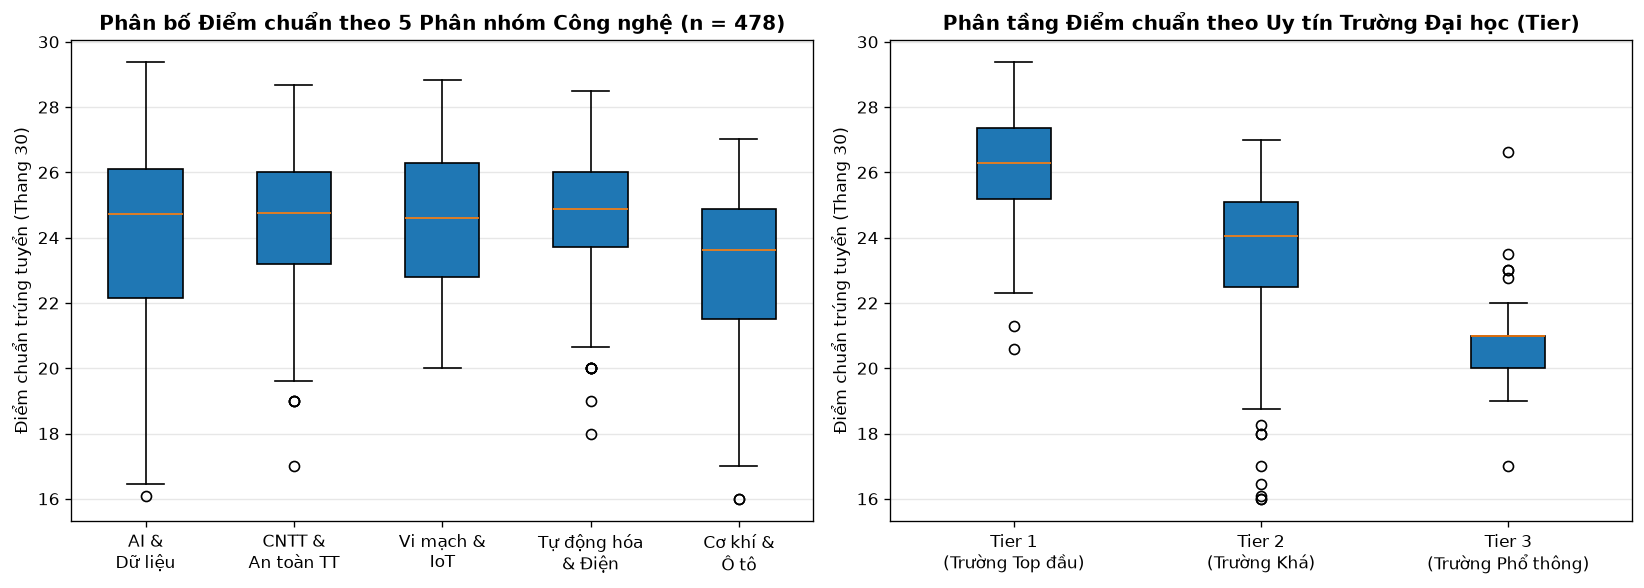

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.0), dpi=120)

thu_tu_nhom = ['AI_DATA', 'SE_CYBER', 'CHIP_IOT_HW', 'AUTO_ELEC', 'MECH_AUTO_TECH']
du_lieu_nhom = [df_full[df_full['ma_nganh_chuan'] == m]['diem_chuan'] for m in thu_tu_nhom]
axes[0].boxplot(du_lieu_nhom, tick_labels=['AI &\nDữ liệu', 'CNTT &\nAn toàn TT', 'Vi mạch &\nIoT', 'Tự động hóa\n& Điện', 'Cơ khí &\nÔ tô'], patch_artist=True)
axes[0].set_title('Phân bố Điểm chuẩn theo 5 Phân nhóm Công nghệ (n = 478)', fontweight='bold')
axes[0].set_ylabel('Điểm chuẩn trúng tuyển (Thang 30)')
axes[0].grid(axis='y', alpha=0.3)

thu_tu_tier = ['Tier 1', 'Tier 2', 'Tier 3']
du_lieu_tier = [df_full[df_full['tier_ranking'] == t]['diem_chuan'] for t in thu_tu_tier]
axes[1].boxplot(du_lieu_tier, tick_labels=['Tier 1\n(Trường Top đầu)', 'Tier 2\n(Trường Khá)', 'Tier 3\n(Trường Phổ thông)'], patch_artist=True)
axes[1].set_title('Phân tầng Điểm chuẩn theo Uy tín Trường Đại học (Tier)', fontweight='bold')
axes[1].set_ylabel('Điểm chuẩn trúng tuyển (Thang 30)')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét và Ý nghĩa thực tiễn tuyển sinh:**
- Biểu đồ bên trái cho thấy sự phân tầng rõ rệt ngay bên trong khối Công nghệ: nhóm `AI_DATA` (AI & Khoa học dữ liệu) và `SE_CYBER` (CNTT & An toàn thông tin) có trung vị điểm chuẩn cao nhất, tiếp đến là nhóm phần cứng – điều khiển (`CHIP_IOT_HW`, `AUTO_ELEC`), trong khi nhóm `MECH_AUTO_TECH` (Cơ khí & Ô tô) có dải điểm rộng và dễ tiếp cận hơn.
- <span style="color: cyan;">Sự khác biệt về mặt bằng điểm và biên độ dao động giữa 5 phân nhóm này chứng minh rằng nếu gộp chung tất cả vào một mô hình duy nhất thì sai số sẽ tăng cao; do đó ở File 6 nhóm tách thành **3 Nhóm Chuyên gia AI** (`G1`: AI/Phần mềm, `G2`: Vi mạch/Tự động hóa, `G3`: Cơ khí/Ô tô).</span>
- Biểu đồ bên phải khẳng định vai trò quyết định của thương hiệu trường đại học (`tier_score`): các trường `Tier 1` (như ĐH Bách khoa Hà Nội, ĐH Công nghệ – ĐHQGHN, HV Công nghệ Bưu chính Viễn thông) có dải điểm tập trung dày đặc ở vùng đỉnh 26–29 điểm và rất ít phương sai.
- Đối với thí sinh có mức điểm từ 23–25 điểm vẫn đam mê ngành AI hoặc Phần mềm, việc lựa chọn các trường nhóm `Tier 2` là chiến lược an toàn và thực tế hơn rất nhiều so với cố đặt toàn bộ nguyện vọng vào nhóm `Tier 1`.

**Đoạn code nhỏ 3 — Phân tích mối quan hệ phi tuyến (`Scatterplot`) và Ma trận tương quan `Pearson` giữa các đặc trưng cốt lõi:**